# ASL Alphabet Sign Recognition: Overall Project Notebook

This notebook brings together the project data exploration and preprocessing with the traditional machine-learning experiment. The role-specific notebooks, `01_data.ipynb` and `02_traditional_ml.ipynb`, are retained unchanged.

## Contents
1. **Data exploration and preprocessing**: image checks, leak-free manifest split, cleaning, augmentation, subsets, and the shared loader.
2. **Traditional ML experiment**: HOG and color-histogram features; logistic regression, random forest, and linear SVM; validation/test evaluation, size comparison, and error analysis.

All experiments use the shared manifest, class order, and seed. The traditional-ML section reads its metrics and log from saved results rather than manually entered scores.


# 01. Data: exploration, cleaning, split, augmentation
**Role 1.** Dataset: [ASL Alphabet](https://www.kaggle.com/datasets/grassknoted/asl-alphabet), 87,000 color images of one hand (200x200 RGB), 29 classes (A-Z, `del`, `nothing`, `space`).

This notebook shows every data step and why it was done:
1. Load and validate
2. Class balance and sample images
3. How the data was recorded (and why a random split leaks)
4. The leak-free split every model uses
5. Cleaning checks
6. Augmentation
7. Subsets for the size and class-count experiments
8. The shared loader and the real-world test set

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

import clean, data, make_manifest

OUT = data.ROOT / 'processed'
plt.rcParams['figure.dpi'] = 100

## 1. Load and validate
One row per image. The number in the file name (`A17.jpg` -> 17) is the frame number, which we will see is the position in the video.

In [2]:
df = data.list_images()
print(len(df), 'images,', df['label'].nunique(), 'classes')
bad, sizes, modes = 0, set(), set()
for p in df['path'].sample(3000, random_state=data.SEED):  # spot check; the full quality scan below reads every file
    try:
        with Image.open(data.TRAIN_DIR / p) as im:
            sizes.add(im.size); modes.add(im.mode)
    except Exception:
        bad += 1
print('unreadable in sample:', bad, '| sizes:', sizes, '| modes:', modes)
print('duplicate paths:', df['path'].duplicated().sum())

87000 images, 29 classes


unreadable in sample: 0 | sizes: {(200, 200)} | modes: {'RGB'}
duplicate paths: 0


**A dataset artifact: every image has a blue border line.** The mean colour of the outermost pixels shows it. It is in every class, so it is not a label shortcut, but webcam photos will not have it and it would be rotated and resized into every training image. We trim `data.EDGE_CROP` = 4 px from each side (200x200 -> 192x192) before any resizing, everywhere in the pipeline: the loader and cache, the quality scan and the YOLO folders.

In [3]:
A = np.stack([np.asarray(Image.open(data.TRAIN_DIR / p).convert('RGB')) for p in df['path'].sample(300, random_state=data.SEED)]).astype(float)
edge = pd.DataFrame({d: np.concatenate([A[:, d].reshape(-1, 3), A[:, -1 - d].reshape(-1, 3), A[:, :, d].reshape(-1, 3), A[:, :, -1 - d].reshape(-1, 3)]).mean(0) for d in range(6)}, index=list('RGB')).T
edge.index.name = 'pixels from edge'; edge.round(0)

,R,G,B
pixels from edge,,,
0,8.0,8.0,193.0
1,69.0,67.0,200.0
2,124.0,122.0,159.0
3,130.0,126.0,121.0
4,130.0,126.0,126.0
5,130.0,126.0,127.0


## 2. Class balance and sample images

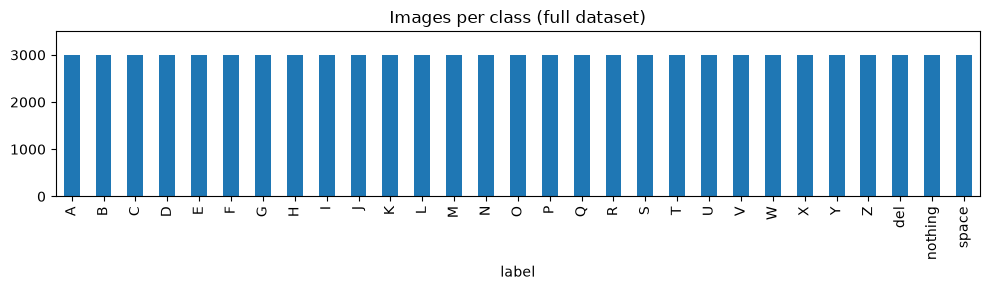

min 3000 | max 3000 -> perfectly balanced, no resampling or class weights needed


In [4]:
counts = df['label'].value_counts().reindex(data.CLASSES)
ax = counts.plot.bar(figsize=(10, 3), title='Images per class (full dataset)', ylim=(0, 3500))
ax.figure.tight_layout(); ax.figure.savefig(OUT / 'class_counts.png', dpi=120); plt.show()
print('min', counts.min(), '| max', counts.max(), '-> perfectly balanced, no resampling or class weights needed')

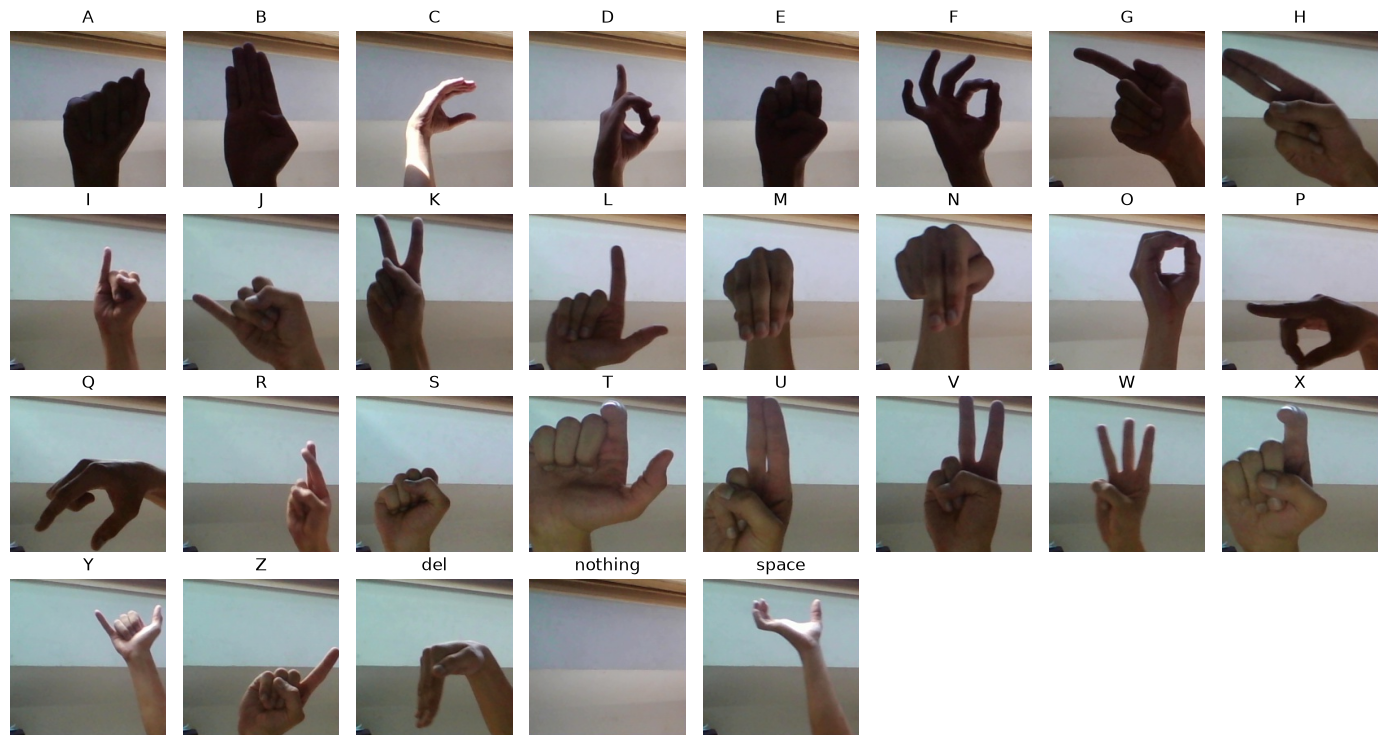

In [5]:
X64 = np.load(data.build_cache(), mmap_mode='r')
fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
for ax in axes.ravel(): ax.axis('off')
for i, c in enumerate(data.CLASSES):
    ax = axes.ravel()[i]
    ax.imshow(data.crop_edge(Image.open(data.TRAIN_DIR / df.loc[(df['y'] == i) & (df['frame'] == 100), 'path'].iloc[0])))
    ax.set_title(c)
fig.tight_layout(); fig.savefig(OUT / 'samples_per_letter.png', dpi=100); plt.show()

## 3. How the data was recorded, and why a random split leaks
Each letter is a continuous video turned into 3,000 frames. If neighbouring frame numbers are neighbouring moments, a random train/test split puts almost the same picture on both sides. We test that directly: compare the pixel difference between frames *k* apart with the difference between two random pictures of the same letter.

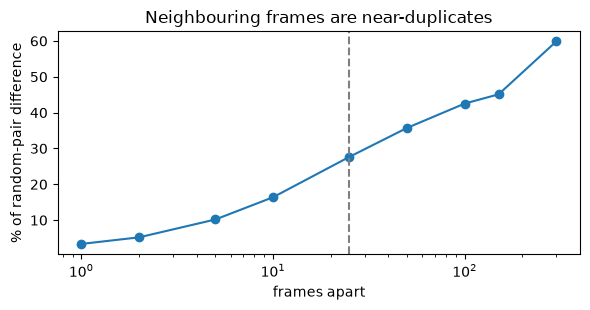

{1: np.float32(3.0), 2: np.float32(5.0), 5: np.float32(10.0), 10: np.float32(16.0), 25: np.float32(28.0), 50: np.float32(36.0), 100: np.float32(43.0), 150: np.float32(45.0), 300: np.float32(60.0)}


In [6]:
F = X64[:].reshape(-1, 16, 4, 16, 4, 3).mean(axis=(2, 4)).reshape(len(X64), -1).astype(np.float32)
y = df['y'].to_numpy()
rng = np.random.default_rng(0)
base = np.median(np.concatenate([np.abs(F[y == c][rng.integers(0, 3000, 1500)] - F[y == c][rng.integers(0, 3000, 1500)]).mean(1) for c in range(29)]))
gaps = [1, 2, 5, 10, 25, 50, 100, 150, 300]
med = [np.median(np.concatenate([np.abs(F[y == c][k:] - F[y == c][:-k]).mean(1) for c in range(29)])) for k in gaps]
plt.figure(figsize=(6, 3.2)); plt.plot(gaps, 100 * np.array(med) / base, 'o-')
plt.axvline(25, ls='--', c='grey'); plt.xscale('log'); plt.xlabel('frames apart'); plt.ylabel('% of random-pair difference')
plt.title('Neighbouring frames are near-duplicates'); plt.tight_layout(); plt.savefig(OUT / 'frame_similarity.png', dpi=120); plt.show()
print(dict(zip(gaps, (100 * np.array(med) / base).round(0))))

Frames 1 apart differ by about 3% of what two random pictures differ; the difference levels off around 25-50 frames. So test images should be at least ~25 frames away from every training image.

**Proof that a random split is broken.** We rebuild the original random 70/15/15 split and score a 1-nearest-neighbour lookup on raw 16x16 pixels. That is not a model, it just finds the most similar training picture.

In [7]:
old = pd.DataFrame({'path': sorted(df['path'])}); old['y'] = old['path'].str.split('/').str[0].map(data.CLASS_TO_Y)
tr, rest = train_test_split(old, test_size=0.30, stratify=old['y'], random_state=data.SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=rest['y'], random_state=data.SEED)
pos = {p: i for i, p in enumerate(df['path'])}
itr_old = np.array([pos[p] for p in tr['path']]); ite_old = np.array([pos[p] for p in te['path']])
sel = np.random.default_rng(1).choice(ite_old, 3000, replace=False)
acc_old = (KNeighborsClassifier(1, n_jobs=-1).fit(F[itr_old], y[itr_old]).predict(F[sel]) == y[sel]).mean()
print(f'random split: 1-NN on raw pixels scores {acc_old:.1%} on the test set')

random split: 1-NN on raw pixels scores 99.7% on the test set


A lookup with no learning scores ~99.7%, so any model would too and the comparison would mean nothing. This is why the split was rebuilt.

**Recording conditions repeat across letters.** Averaging brightness over 150-frame blocks shows the same pattern for almost every letter: frames ~1050-1950 are bright and ~1950-2400 are dim. Frame number is a proxy for recording session, so a good split must show every model every lighting condition.

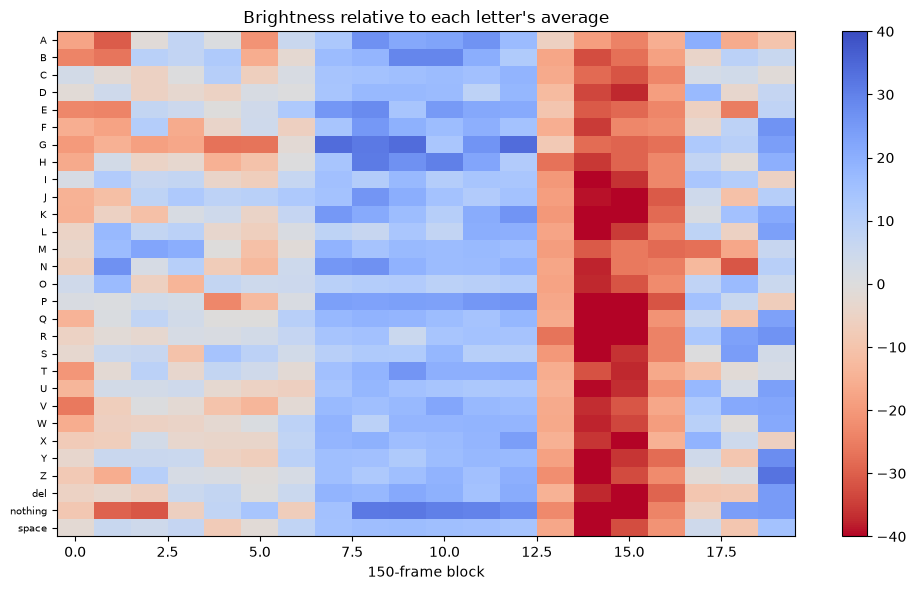

bright        [7, 8, 9, 10, 11, 12, 19]
dim                    [13, 14, 15, 16]
normal    [0, 1, 2, 3, 4, 5, 6, 17, 18]


In [8]:
q = clean.quality_scan().set_index('path').loc[df['path']].reset_index()
q['y'], q['block'] = df['y'], (df['frame'] - 1) // make_manifest.BLOCK
t = q.groupby(['y', 'block'])['brightness'].mean().unstack()
rel = t.sub(t.mean(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 6)); im = ax.imshow(rel, cmap='coolwarm_r', vmin=-40, vmax=40, aspect='auto')
ax.set_yticks(range(29)); ax.set_yticklabels(data.CLASSES, fontsize=7); ax.set_xlabel('150-frame block'); ax.set_title('Brightness relative to each letter\'s average')
plt.colorbar(im); fig.tight_layout(); fig.savefig(OUT / 'brightness_by_block.png', dpi=120); plt.show()
regimes = make_manifest.block_regimes(q); print(regimes.groupby(regimes).apply(lambda s: list(s.index)).to_string())

## 4. The leak-free split
Built by `make_manifest.py` and saved to `processed/asl_alphabet_manifest.csv`. **Nobody makes their own split.**

1. Cut each letter into 20 blocks of 150 consecutive frames.
2. Group blocks into dim / normal / bright regimes (above).
3. Per letter: one random block per regime goes to val, one per regime to test, the other 14 to train. Every split sees every lighting condition.
4. Drop 25 frames on each side of every train/val/test boundary (`split = 'buffer'`).

In [9]:
m = make_manifest.build_manifest()
make_manifest.verify(m)   # raises if any val/test frame is within 25 frames of a train frame, or a lighting regime is missing from a split
m.to_csv(data.MANIFEST_PATH, index=False)
print(m['split'].value_counts().to_string())
pd.crosstab(m['label'], m['split']).reindex(data.CLASSES).T

split
train     54900
buffer    14000
val        9225
test       8875


label,A,B,C,D,E,F,G,H,I,J,...,T,U,V,W,X,Y,Z,del,nothing,space
split,,,,,,,,,,,,,,,,,,,,,
buffer,450,450,450,250,450,500,550,500,550,550,...,550,450,500,450,500,450,450,400,450,450
test,300,300,300,350,300,300,300,300,300,300,...,300,300,300,300,300,300,300,350,325,300
train,1925,1925,1925,2025,1900,1900,1850,1900,1850,1850,...,1850,1900,1875,1900,1875,1925,1950,1925,1925,1925
val,325,325,325,375,350,300,300,300,300,300,...,300,350,325,350,325,325,300,325,300,325


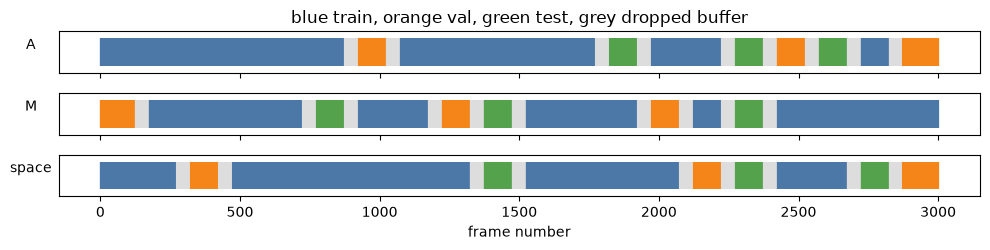

In [10]:
# Which frames go where, for three example letters
colors = {'train': '#4c78a8', 'val': '#f58518', 'test': '#54a24b', 'buffer': '#dddddd'}
fig, axes = plt.subplots(3, 1, figsize=(10, 2.6), sharex=True)
for ax, c in zip(axes, ['A', 'M', 'space']):
    f = m[m['label'] == c]
    ax.scatter(f['frame'], np.zeros(len(f)), c=f['split'].map(colors), marker='|', s=400)
    ax.set_yticks([]); ax.set_ylabel(c, rotation=0, labelpad=20)
axes[-1].set_xlabel('frame number')
axes[0].set_title('blue train, orange val, green test, grey dropped buffer')
fig.tight_layout(); fig.savefig(OUT / 'split_layout.png', dpi=120); plt.show()

In [11]:
Xtr, ytr = data.load_split('train'); Xte, yte = data.load_split('test')
F2 = lambda X: X.reshape(len(X), 16, 4, 16, 4, 3).mean(axis=(2, 4)).reshape(len(X), -1) * 255
s = np.random.default_rng(1).choice(len(Xte), 3000, replace=False)
acc_new = (KNeighborsClassifier(1, n_jobs=-1).fit(F2(Xtr), ytr).predict(F2(Xte[s])) == yte[s]).mean()
print(f'1-NN on raw pixels:  random split {acc_old:.1%}  ->  time-block split {acc_new:.1%}')

1-NN on raw pixels:  random split 99.7%  ->  time-block split 45.5%


The same lookup falls from ~99.7% to ~45%, so the test set now needs a model that has learned the sign rather than memorised a frame. **Caveat for the write-up:** all 87,000 images show the same hand and room. The new split removes frame leakage but not signer or background similarity, which is why the real-world test set (section 8) is the honest measure of webcam performance.

## 5. Cleaning checks
`clean.py` reads every original image and measures brightness, contrast, sharpness (variance of the Laplacian) and two hashes.

In [12]:
print('exact duplicate files:', q['md5'].duplicated(keep=False).sum())
print('brightness range: %.0f-%.0f (0-255) | contrast range %.0f-%.0f' % (q.brightness.min(), q.brightness.max(), q.contrast.min(), q.contrast.max()))
bg = pd.DataFrame({'blur_flag': m.groupby('label')['blur_flag'].mean().reindex(data.CLASSES)})
print('images flagged blurry (robust z < %.1f within letter and lighting): %d' % (make_manifest.BLUR_Z, m['blur_flag'].sum()))

exact duplicate files: 0


brightness range: 65-195 (0-255) | contrast range 18-100
images flagged blurry (robust z < -3.5 within letter and lighting): 111


**What the checks found.**
- No unreadable files, no exact duplicates, every image 200x200 RGB.
- Raw sharpness is misleading across classes (the plain-wall `nothing` frames look "blurry" because they have no texture), so blur is judged *within* each letter and lighting regime.
- The dark and blurry frames are the dim recording session described above: real lighting variation a webcam will also produce. We **flag but keep** them (`blur_flag` column) and rely on brightness augmentation, because deleting hard frames would make the test set easier.
- Letters flagged as "closest to the empty background" were inspected and all show a clear hand, so no empty-frame mislabels were found.

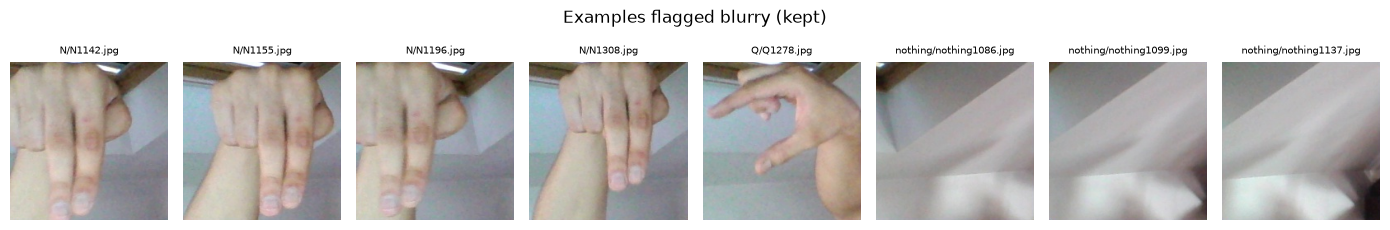

In [13]:
fl = m[m['blur_flag']].groupby('label').size().reindex(data.CLASSES).fillna(0)
idx = m.index[m['blur_flag']][:: max(1, m['blur_flag'].sum() // 8)][:8]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, i in zip(axes, idx):
    ax.imshow(data.crop_edge(Image.open(data.TRAIN_DIR / m.loc[i, 'path']))); ax.set_title(m.loc[i, 'path'], fontsize=7); ax.axis('off')
fig.suptitle('Examples flagged blurry (kept)'); fig.tight_layout(); fig.savefig(OUT / 'blur_flagged.png', dpi=100); plt.show()

**Look-alike letters, not label errors.** Some images share a perceptual hash with an image of a *different* letter. Counting which letter pairs collide predicts where models will confuse letters, useful for Role 2's error analysis.

In [14]:
h = q.assign(label=df['label']).groupby('dhash')['label'].agg(lambda s: tuple(sorted(set(s))))
h = h[h.map(len) > 1]
pairs = h.value_counts().head(10).rename('shared hashes')
print('images sharing a hash with another letter:', int(m['confusable_hash'].sum()))
pairs

images sharing a hash with another letter: 2673


label
(R, U)    35
(U, V)    18
(V, W)    15
(R, V)    10
(K, V)     9
(S, X)     7
(S, U)     7
(N, O)     6
(K, W)     6
(B, E)     6
Name: shared hashes, dtype: int64

## 6. Augmentation
`data.augment()` makes randomly rotated (+-15 deg), zoomed (0.9-1.15x), shifted (+-8%), brightened (0.6-1.4x) and contrast-changed copies. It is for **training images only**, never val or test. Mirroring is off by default because a mirrored hand is a left-hand sign; turn on `flip=True` only if the webcam preview is mirrored. The brightness range is wide on purpose, to cover the dim session.

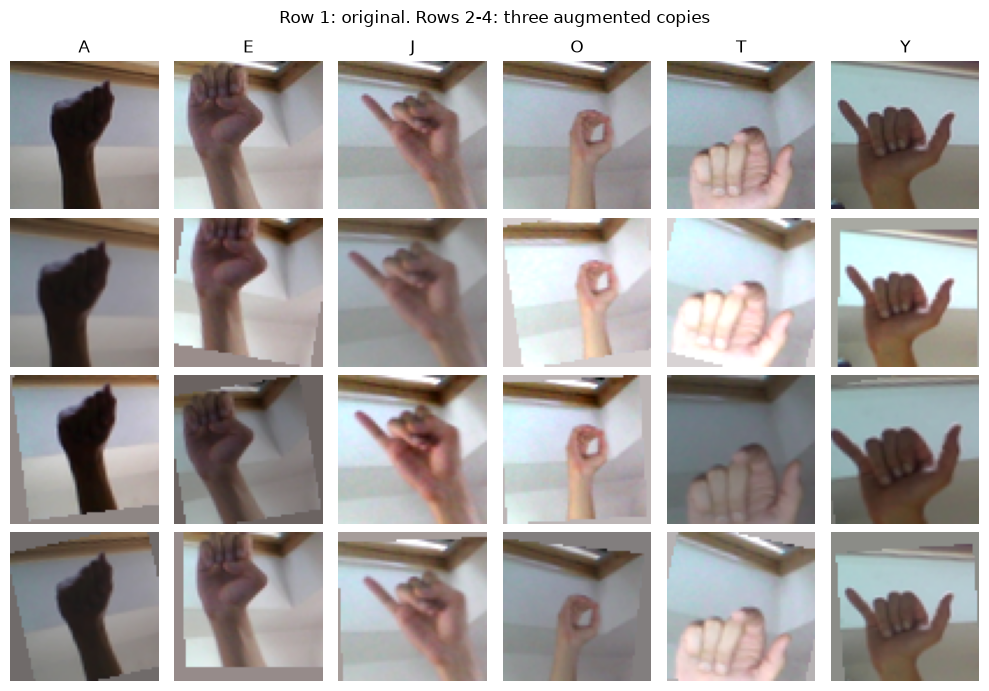

In [15]:
ex = Xtr[np.arange(0, len(Xtr), len(Xtr) // 6)[:6]]
aug = [data.augment(ex, seed=k) for k in (1, 2, 3)]
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for j in range(6):
    for r, arr in enumerate([ex] + aug):
        axes[r, j].imshow(arr[j]); axes[r, j].axis('off')
    axes[0, j].set_title(data.CLASSES[ytr[np.arange(0, len(Xtr), len(Xtr) // 6)[j]]])
axes[0, 0].set_ylabel('original')
fig.suptitle('Row 1: original. Rows 2-4: three augmented copies'); fig.tight_layout(); fig.savefig(OUT / 'augmentation.png', dpi=100); plt.show()

## 7. Subsets for the size and class-count experiments
- **10k subset:** 345 training images per letter (10,005), picked at even spacing so every recording and lighting condition is represented. Only training shrinks; val and test stay full so results are comparable with the full-data run.
- **10-class subset:** `data.TEN_CLASSES` = A, B, E, L, M, N, S, V, W, Y, five look-alike fists plus five distinct shapes. All three splits are restricted to these letters and labels are 0-9.

In [16]:
rows = []
for name, sub in [('full', None), ('10k', '10k'), ('10class', '10class')]:
    rows.append({'variant': name, **{s: len(data.load_manifest(s, sub)) for s in ['train', 'val', 'test']}})
pd.DataFrame(rows).set_index('variant')

,train,val,test
variant,,,
full,54900,9225,8875
10k,10005,9225,8875
10class,18875,3225,3050


## 8. The shared loader and the real-world test set
Everyone gets data with `data.load_split`. Labels are positions in `data.CLASSES` in every notebook.

In [17]:
X, y_ = data.load_split('val', size=64, color=True)
Xg, _ = data.load_split('val', size=28, color=False)
X10, y10 = data.load_split('train', subset='10class', dtype='uint8')
print(X.shape, X.dtype, '| gray 28:', Xg.shape, '| 10-class:', X10.shape, X10.dtype, sorted(set(y10)))
assert list(m['label'].unique()) == data.CLASSES

(9225, 64, 64, 3) float32 | gray 28: (9225, 28, 28, 1) | 10-class: (18875, 64, 64, 3) uint8 [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


```python
from data import load_split, class_names, augment, load_real_world
X_train, y_train = load_split('train', size=64, color=True)             # float32 in [0, 1], shape (N, 64, 64, 3)
X_val, y_val = load_split('val', subset='10class')                      # 10 letters, labels 0-9, class_names('10class')
X_small, y_small = load_split('train', size=224, subset='10k', dtype='uint8')   # larger sizes are decoded from the JPEGs
```
Sizes up to 64 come from a cache; larger sizes are read from the images, and requests over ~4 GB raise an error (use `subset='10k'`).

**Real-world test set.** The dataset has one signer and one room, so test scores will look better than a live webcam. Everyone takes a few photos of each letter with their own phone or webcam and adds them with `data.ingest_real_world(folder_with_one_subfolder_per_letter, person='yourname')`. `data.load_real_world()` then returns them in the same format as `load_split`, so every model can also be scored on photos it has never seen.

In [18]:
print('real-world photos collected so far:', len(data.real_world_files()))

real-world photos collected so far: 0


## Hand-off
- `processed/asl_alphabet_manifest.csv` is the single split (train 54,900 / val 9,225 / test 8,875; 14,000 buffer frames unused).
- `data.py` is the shared loader, with augmentation, subsets and the real-world set.
- `data.make_yolo_folders()` builds the YOLO classification layout (edge-cropped copies) from the same split.
- Open item: collect real-world photos. The traditional-ML section below uses the look-alike pairs above for error analysis.

# 02. Traditional ML: HOG and color-histogram baselines

**Role 2.** This section reports the traditional-ML experiment on the ASL Alphabet dataset. It uses the single manifest split and shared loader described in the data section above; it does not create another split or change label meanings.

The experiment compares logistic regression, random forest, and linear SVM on 10,005 versus 54,900 training images. Validation is used for model selection and the fixed test set is reported once. The result cells below load the saved shared-evaluator reports, comparison figures, and experiment log; they do not retrain the models. To reproduce training into a fresh output directory, configure `ASL_DATA_DIR` and run `python experiment1.py --results-dir results/experiment1_rerun` from the repository root. Trained wrappers are saved as `results/experiment1_<model>_<data-variant>_model.joblib`; run `python experiment1.py --export-models` to export wrappers matching an existing run. Each wrapper implements `predict(rgb_image) -> (letter, confidence)` for a single preprocessed 64 x 64 uint8 RGB image.

**Notebook contents**
1. Experimental methods and features
2. Shared evaluation and model comparison
3. Confusion analysis and limitations


## 1. Experimental results: traditional ML

### Goal and controlled comparison

This experiment compares logistic regression, a random forest, and a linear support vector machine (SVM) on the 29 ASL Alphabet classes. It also measures how training-set size affects each model. We use the shared, time-blocked manifest split described above rather than making a new random split: 54,900 full-training images, a 10,005-image subset, 9,225 validation images, and the same 8,875 test images for every model. The subset contains 345 training images per class; validation and test remain unchanged.

### Image preprocessing and features

The shared loader removes the 4-pixel border, resizes each RGB image to 64 x 64, and preserves the manifest labels. Features are extracted once and reused for both training-set sizes:

1. Convert each image to grayscale and compute Histogram of Oriented Gradients (HOG): 9 orientations, 16 x 16-pixel cells, 2 x 2-cell blocks, and L2-Hys normalization. This yields 324 features describing local hand edges and shape.
2. For each of the three RGB channels, compute an 8-bin histogram and divide bin counts by the number of pixels. This adds 24 color-distribution features.
3. Concatenate the two parts into one 348-feature vector. The resulting feature matrices are shared by all three models.

Logistic regression uses `max_iter=1000`; the random forest uses 100 trees; the SVM is `LinearSVC` with `max_iter=5000`. All use seed 42. Logistic regression and SVM standardize features using statistics fit on training data only; the forest uses unscaled features. These settings were fixed for the comparison, not tuned on the test set.

### Evaluation protocol

Each fitted model predicts the unchanged validation and test sets. The shared `evaluate.py` scorer reports accuracy, macro- and support-weighted precision, recall and F1, per-class scores, and a confusion matrix in the fixed class order. Training duration is recorded. CPU inference latency is measured on 200 evenly spaced, already-preprocessed test images, one image at a time; it includes HOG and color-histogram extraction plus prediction. The saved model wrapper accepts one 64 x 64 uint8 RGB image from the shared preprocessing and returns `(letter, confidence)`. Logistic regression and random forest use their predicted-class probabilities; the SVM confidence is a softmax of decision scores and is not calibrated. These timings depend on the machine and are not end-to-end webcam latency.

The cells below load the saved reports and artifacts from `results/`. Re-running this results section does not retrain the classifiers. To reproduce training, first make sure `ASL_DATA_DIR` points to the image dataset and run `python experiment1.py` from the repository root.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import evaluate

RESULTS_DIR = Path("results")
ARTIFACT_DIR = RESULTS_DIR / "experiment1"
comparison = pd.read_csv(ARTIFACT_DIR / "comparison.csv")
comparison = comparison.rename(columns={
    "val_accuracy": "validation_accuracy",
    "test_macro_precision": "macro_precision",
    "test_macro_recall": "macro_recall",
    "test_macro_f1": "macro_f1",
})

assert len(comparison) == 6
assert set(comparison["n_train"]) == {10005, 54900}
assert comparison["test_accuracy"].between(0, 1).all()

display(comparison[[
    "model", "training_size", "n_train", "validation_accuracy", "test_accuracy",
    "macro_precision", "macro_recall", "macro_f1", "train_time_s", "inference_ms"
]].style.format({
    "validation_accuracy": "{:.2%}", "test_accuracy": "{:.2%}",
    "macro_precision": "{:.2%}", "macro_recall": "{:.2%}", "macro_f1": "{:.2%}",
    "train_time_s": "{:.1f}", "inference_ms": "{:.2f}"
}))

# Keep this run in the shared log used by the experiment table and slides.
experiment_log = pd.read_csv(RESULTS_DIR / "experiment_log.csv")
experiment1_log = experiment_log[experiment_log["run_id"].str.startswith("experiment1_")]
display(experiment1_log)

size_test = comparison.pivot(index="model", columns="training_size", values="test_accuracy")
size_test["full_minus_10k_percentage_points"] = (size_test["full"] - size_test["10k"]) * 100
print("Test-accuracy change from 10k to full training data:")
display(size_test)

best_validation = comparison.loc[comparison["validation_accuracy"].idxmax()]
best_test = comparison.loc[comparison["test_accuracy"].idxmax()]
print(f"Highest validation accuracy: {best_validation['model']} ({best_validation['training_size']}, {best_validation['validation_accuracy']:.2%})")
print(f"Highest test accuracy (report only; not used for model selection): {best_test['model']} ({best_test['training_size']}, {best_test['test_accuracy']:.2%})")


### Comparison and size-test results

Each row uses the same fixed test set. Accuracy is the fraction of correct predictions; macro precision, recall and F1 average per-letter scores equally, so a class with fewer test frames is not hidden by frequent classes. The shared `results/experiment_log.csv` is the run log and source for the experiment table; the code cell above loads it alongside the saved JSON reports. Metrics are not manually retyped into another spreadsheet.

The table below compares validation and test metrics, training time and batch-one CPU latency for all six runs. The shared chart is generated from these saved reports, and the next code cell can recreate it from the comparison table.

![Experiment 1 comparison chart](results/experiment1/comparison.png)

Use validation results for model selection, not the held-out test scores. Each row is a single fixed-parameter run, not an uncertainty estimate. Inference latency depends on the CPU and machine load.


In [ ]:
labels = comparison["model"] + "\n" + comparison["training_size"]
positions = np.arange(len(comparison))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for offset, (column, label) in enumerate((
    ("test_accuracy", "Accuracy"),
    ("macro_precision", "Macro precision"),
    ("macro_recall", "Macro recall"),
    ("macro_f1", "Macro F1"),
)):
    axes[0].bar(positions + (offset - 1.5) * 0.2, comparison[column], width=0.2, label=label)
axes[0].set_xticks(positions, labels)
axes[0].set_ylim(0, 1)
axes[0].set_title("Test metrics")
axes[0].legend()

for ax, column, title in zip(
    axes[1:], ("train_time_s", "inference_ms"),
    ("Training time (seconds)", "CPU batch-one inference (ms/image)"),
):
    ax.bar(labels, comparison[column])
    ax.set_title(title)
for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)
fig.tight_layout()
plt.show()

### Error analysis: which letters are confused?

The full-data random forest has the highest test accuracy in this comparison. The table and normalized confusion matrix below are generated from its shared test report. The confusion pairs are directed (true letter to predicted letter); the matrix rows are normalized by true class, so the diagonal represents per-letter recall.

![Full-data random forest normalized test confusion matrix](results/experiment1/random_forest_full_confusion.png)

These are video frames, not independent signers, and neighboring frames can show nearly the same pose. A high count is therefore not the same as independent evidence about generalization. The saved prediction CSV links every result back to its original image path.


In [ ]:
report_path = RESULTS_DIR / "experiment1_random_forest_full_test.json"
rf_test = json.loads(report_path.read_text(encoding="utf-8"))

print("Most frequent directed confusions (full-data random forest):")
display(evaluate.top_confusions(rf_test, k=10))

per_class = pd.DataFrame(rf_test["per_class"]).T
per_class.index.name = "letter"
print("Lowest-recall classes:")
display(per_class.sort_values("recall").head(8).style.format({"precision": "{:.1%}", "recall": "{:.1%}", "f1": "{:.1%}", "support": "{:.0f}"}))

conditions = pd.read_csv(ARTIFACT_DIR / "random_forest_full_conditions.csv")
lighting = conditions.loc[conditions["condition"] == "lighting"].copy()
lighting["error_rate"] = lighting["error_rate"].astype(float)
print("Error rates by lighting and image-quality flags:")
display(conditions[["condition", "value", "count", "errors", "error_rate"]].style.format({"error_rate": "{:.1%}"}))

ax = lighting.set_index("value")["error_rate"].plot.bar(
    color=["#f58518", "#4c78a8", "#54a24b"],
    title="Full-data random forest: test error by lighting condition",
    ylabel="Misclassification rate", xlabel="Lighting",
    ylim=(0, 1), rot=0,
)
ax.figure.tight_layout()
plt.show()

### Interpreting the errors and limitations

A visual check of representative misclassified frames suggests plausible reasons, not proven causes. The D example has a prominent curled-finger loop that can resemble O. Some M -> A examples come from dim blocks, where the fist is dark and individual fingers are partly occluded. G/H and U/V differ in finger orientation or spacing; small shape details may not survive 64 x 64 pixels, coarse HOG cells, and a global color histogram. Representative paths include `D/D2580.jpg`, `M/M2328.jpg`, `G/G1608.jpg`, `U/U1136.jpg`, and `V/V1292.jpg`; all predictions and paths are in `results/experiment1/random_forest_full_predictions.csv`.

The grouped error rates by lighting and perceptual-hash flag are shown in the previous cell. They are associations, not causal experiments: lighting and recording blocks are related, and perceptual-hash overlap may mark inherently similar poses. The blur-flag sample is too small for a reliable conclusion.

All images come from one signer and room, even though the time-block split prevents neighboring frames from leaking across train and test. Therefore, these scores do not estimate performance on new signers or webcam conditions. A useful next experiment is to test lighting augmentation and finer shape features using validation results, then evaluate once on a separate set collected from new signers and rooms. The full error-pair rankings, condition summaries, per-image predictions, and model reports are saved under `results/experiment1/` and `results/`.

# 03. CNN: custom architectures and transfer learning

**Role 3.** This notebook reports the CNN classification experiment on the ASL Alphabet dataset. It uses the single manifest split and the shared loader from [01_data.ipynb](01_data.ipynb); it does not create another split or change label meanings.

The experiment compares simple and complex CNN architectures trained from scratch with a pretrained MobileNetV2 model. Additional experiments evaluate training augmentation, color versus grayscale images, image resolution, and classification using 29 versus 10 classes. Validation is used for model selection, and the fixed test sets are used for final evaluation.

The result cells below load the saved shared-evaluator reports, comparison figures, training histories, and experiment log; they do not retrain the models. To reproduce training into a fresh output directory, configure `ASL_DATA_DIR` and run `python experiment2.py --results-dir results/experiment2_rerun` from the repository root. Trained models are saved as `results/experiment2_<configuration>_model.keras`. Each model can be loaded using the `CNNASLModel` wrapper in `cnn_model.py`, which implements `predict(rgb_image) -> (letter, confidence)` for a single preprocessed 64 x 64 uint8 RGB image.

**Notebook contents**
1. Experimental methods and CNN architectures
2. Shared evaluation and model comparison
3. Confusion analysis and limitations

## 1. Experimental methods and CNN architectures

### Goal and controlled comparison

This experiment evaluates whether deeper CNN architectures and pretrained image features improve ASL Alphabet classification. We use the shared, time-blocked manifest split rather than creating a new random split: 54,900 training images, 9,225 validation images, and 8,875 test images for the full 29-class experiments.

The simple CNN, complex CNN, and pretrained MobileNetV2 are compared using the same 64 x 64 RGB images. Additional configurations change one experimental setting relative to the complex CNN baseline.

### Image preprocessing

The shared loader removes the 4-pixel border, resizes images to the specified resolution, and preserves the manifest labels. Images are loaded as uint8 arrays, and pixel normalization is performed within each CNN architecture.

Training augmentation uses the shared augmentation function to apply rotations, zoom, shifts, brightness changes, and contrast changes. Augmentation is applied only to training images, while validation and test images remain unchanged.

### CNN architectures

1. **Simple CNN:** Two convolutional layers with 32 and 64 filters, max pooling, flattening, a dense layer with 128 units, and a softmax output layer.

2. **Complex CNN:** Three convolutional layers with 32, 64, and 128 filters, batch normalization, max pooling, global average pooling, a dense layer with 128 units, dropout of 0.5, and a softmax output layer.

3. **Pretrained MobileNetV2:** A frozen convolutional base with ImageNet weights, followed by global average pooling, a dense layer with 128 units, dropout of 0.5, and a softmax output layer. Only the classification head is trained.

### Experimental configurations

- Simple CNN using 64 x 64 RGB images.
- Complex CNN using 64 x 64 RGB images.
- Complex CNN with training augmentation.
- Complex CNN using 64 x 64 grayscale images.
- Complex CNN using 32 x 32 RGB images.
- Complex CNN using a reduced subset of 10 classes.
- Pretrained MobileNetV2 using 64 x 64 RGB images.

All configurations use the Adam optimizer, sparse categorical cross-entropy loss, a batch size of 32, 10 training epochs, and random seed 42. The augmented configuration contains twice as many training images and therefore performs more training steps. The 10-class configuration uses a reduced set of classes across all three splits and is treated as a separate classification task.

### Evaluation protocol

Each trained model predicts its corresponding validation and test sets. The shared `evaluate.py` scorer reports accuracy, macro- and support-weighted precision, recall and F1, per-class scores, and a confusion matrix. Training duration is also recorded.

CPU inference latency is measured on 200 evenly spaced test images, one image at a time, using the saved model wrapper. Timing includes prediction and any configuration-specific conversion or resizing performed by the wrapper. These measurements depend on the machine and are not end-to-end webcam latency.

Model selection is based on validation accuracy using final-epoch weights. Each configuration represents one fixed-parameter run.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image

import data
import evaluate
from experiment2 import make_experiments

RESULTS_DIR = Path("results")
ARTIFACT_DIR = RESULTS_DIR / "experiment2"

print("Shared manifest split:")
manifest = data.load_manifest()
display(manifest["split"].value_counts())

print("Experimental configurations:")
experiments = pd.DataFrame(make_experiments()).T
display(experiments)

comparison = pd.read_csv(ARTIFACT_DIR / "comparison.csv")

assert len(comparison) == 7
assert comparison["test_accuracy"].between(0, 1).all()

timing_rows = []

for run_id in comparison["run_id"]:
    report_path = RESULTS_DIR / f"{run_id}_test.json"
    result = json.loads(report_path.read_text(encoding="utf-8"))

    timing = result["inference_ms_per_image"]

    timing_rows.append({
        "run_id": run_id,
        "parameters": result["settings"]["parameters"],
        "inference_ms": timing["mean"],
        "median_ms": timing["median"],
        "p95_ms": timing["p95"]
    })

timing_comparison = pd.DataFrame(timing_rows)

comparison = comparison.merge(timing_comparison, on="run_id")

print("Model comparison:")
display(comparison[[
    "data_variant", "n_train", "num_classes",
    "val_accuracy", "test_accuracy",
    "test_macro_precision", "test_macro_recall",
    "test_macro_f1", "train_time_s", "inference_ms"
]].style.format({
    "val_accuracy": "{:.2%}",
    "test_accuracy": "{:.2%}",
    "test_macro_precision": "{:.2%}",
    "test_macro_recall": "{:.2%}",
    "test_macro_f1": "{:.2%}",
    "train_time_s": "{:.1f}",
    "inference_ms": "{:.2f}"
}))

print("Model parameters and CPU inference latency:")
display(comparison[[
    "data_variant", "parameters", "inference_ms",
    "median_ms", "p95_ms"
]].style.format({
    "parameters": "{:,}",
    "inference_ms": "{:.2f}",
    "median_ms": "{:.2f}",
    "p95_ms": "{:.2f}"
}))

experiment_log = pd.read_csv(RESULTS_DIR / "experiment_log.csv")

experiment2_log = experiment_log[
    experiment_log["run_id"].str.startswith("experiment2_")
]

display(experiment2_log)

full_comparison = comparison[
    comparison["num_classes"] == 29
].copy()

best_validation = full_comparison.loc[
    full_comparison["val_accuracy"].idxmax()
]

print(
    f"Highest validation accuracy: "
    f"{best_validation['data_variant']} "
    f"({best_validation['val_accuracy']:.2%})"
)

print(
    f"Selected model test accuracy: "
    f"{best_validation['test_accuracy']:.2%}"
)

Shared manifest split:


split
train     54900
buffer    14000
val        9225
test       8875
Name: count, dtype: int64

Experimental configurations:


,model,size,color,subset,augmentation
simple_cnn_rgb64,simple_cnn,64,True,None,False
complex_cnn_rgb64,complex_cnn,64,True,None,False
complex_cnn_augmented,complex_cnn,64,True,None,True
complex_cnn_grayscale,complex_cnn,64,False,None,False
complex_cnn_rgb32,complex_cnn,32,True,None,False
complex_cnn_10class,complex_cnn,64,True,10class,False
pretrained_cnn_rgb64,pretrained_cnn,64,True,None,False


Model comparison:


,data_variant,n_train,num_classes,val_accuracy,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,train_time_s,inference_ms
0,simple_cnn_rgb64,54900,29,62.02%,61.22%,62.54%,61.23%,60.86%,704.7,8.81
1,complex_cnn_rgb64,54900,29,88.89%,86.78%,87.66%,87.03%,86.54%,1704.2,13.54
2,complex_cnn_augmented,109800,29,85.46%,85.51%,87.55%,85.42%,85.36%,3287.7,17.46
3,complex_cnn_grayscale,54900,29,80.18%,78.50%,85.95%,78.66%,79.61%,1870.2,12.75
4,complex_cnn_rgb32,54900,29,85.31%,84.55%,85.67%,84.46%,84.40%,516.1,11.72
5,complex_cnn_10class,18875,10,46.11%,38.39%,55.53%,39.03%,35.47%,607.7,12.12
6,pretrained_cnn_rgb64,54900,29,63.45%,65.87%,66.77%,65.93%,65.73%,1520.6,106.71


Model parameters and CPU inference latency:


,data_variant,parameters,inference_ms,median_ms,p95_ms
0,simple_cnn_rgb64,"1,628,893",8.81,7.99,13.15
1,complex_cnn_rgb64,"114,397",13.54,13.04,15.38
2,complex_cnn_augmented,"114,397",17.46,15.53,31.32
3,complex_cnn_grayscale,"113,821",12.75,12.40,14.55
4,complex_cnn_rgb32,"114,397",11.72,11.43,14.09
5,complex_cnn_10class,"111,946",12.12,12.01,13.20
6,pretrained_cnn_rgb64,"2,425,693",106.71,103.29,121.74


,run_id,owner,model,data_variant,key_settings,val_accuracy,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,train_time_s,notes
6,experiment2_simple_cnn_rgb64,Nancy Vutuan,simple_cnn,simple_cnn_rgb64,"{""augmentation"": false, ""batch_size"": 32, ""col...",0.620163,0.612169,0.625367,0.612265,0.608611,704.697600,Fixed manifest split; final epoch weights.
7,experiment2_complex_cnn_rgb64,Nancy Vutuan,complex_cnn,complex_cnn_rgb64,"{""augmentation"": false, ""batch_size"": 32, ""col...",0.888889,0.867831,0.876562,0.870345,0.865398,1704.210470,Fixed manifest split; final epoch weights.
8,experiment2_complex_cnn_augmented,Nancy Vutuan,complex_cnn,complex_cnn_augmented,"{""augmentation"": true, ""batch_size"": 32, ""colo...",0.854634,0.855099,0.875538,0.854236,0.853575,3287.691341,Fixed manifest split; final epoch weights.
9,experiment2_complex_cnn_grayscale,Nancy Vutuan,complex_cnn,complex_cnn_grayscale,"{""augmentation"": false, ""batch_size"": 32, ""col...",0.801843,0.785014,0.859499,0.786626,0.796128,1870.151278,Fixed manifest split; final epoch weights.
10,experiment2_complex_cnn_rgb32,Nancy Vutuan,complex_cnn,complex_cnn_rgb32,"{""augmentation"": false, ""batch_size"": 32, ""col...",0.853117,0.845521,0.856709,0.844565,0.844028,516.122065,Fixed manifest split; final epoch weights.
11,experiment2_complex_cnn_10class,Nancy Vutuan,complex_cnn,complex_cnn_10class,"{""augmentation"": false, ""batch_size"": 32, ""col...",0.461085,0.383934,0.555325,0.390333,0.354703,607.696217,Fixed manifest split; final epoch weights.
12,experiment2_pretrained_cnn_rgb64,Nancy Vutuan,pretrained_cnn,pretrained_cnn_rgb64,"{""augmentation"": false, ""batch_size"": 32, ""col...",0.634472,0.658704,0.667728,0.659299,0.657346,1520.561212,Fixed manifest split; final epoch weights.


Highest validation accuracy: complex_cnn_rgb64 (88.89%)
Selected model test accuracy: 86.78%


## 2. Shared evaluation and model comparison

### Comparison results

Accuracy measures the fraction of correct predictions, while macro precision, recall, and F1 give equal importance to each class. The shared `results/experiment_log.csv` records the experimental configurations and evaluation results.

The complex CNN using 64 x 64 RGB images achieved the highest validation accuracy of 88.89%, with a test accuracy of 86.78% and macro F1 score of 86.54%.

The following observations summarize the experimental results:

- **Architecture complexity:** The complex CNN achieved 86.78% test accuracy compared with 61.22% for the simple CNN. Additional convolutional layers and regularization may have contributed to improved generalization.

- **Training augmentation:** The augmented complex CNN achieved 85.51% test accuracy, compared with 86.78% without augmentation. Augmentation did not improve performance under the selected training settings.

- **Color versus grayscale:** RGB images achieved 86.78% test accuracy, while grayscale images achieved 78.50%. Color information appears useful for distinguishing signs in this dataset.

- **Image resolution:** Reducing the resolution from 64 x 64 to 32 x 32 decreased test accuracy to 84.55%, but reduced training time by approximately 69.7%.

- **Number of classes:** The 10-class configuration achieved 38.39% test accuracy. Although fewer classes might be expected to simplify classification, this configuration also contains fewer training images and a different class distribution.

- **Transfer learning:** The frozen MobileNetV2 model achieved 65.87% test accuracy. The custom complex CNN performed better under the selected training settings. Fine-tuning the pretrained layers may produce different results.

The comparison chart excludes the 10-class configuration because it uses a different classification task.

![Experiment 2 comparison chart](results/experiment2/comparison.png)

Use validation results for model selection rather than held-out test scores. Each configuration represents one fixed-parameter run, not an estimate of variability across multiple runs.

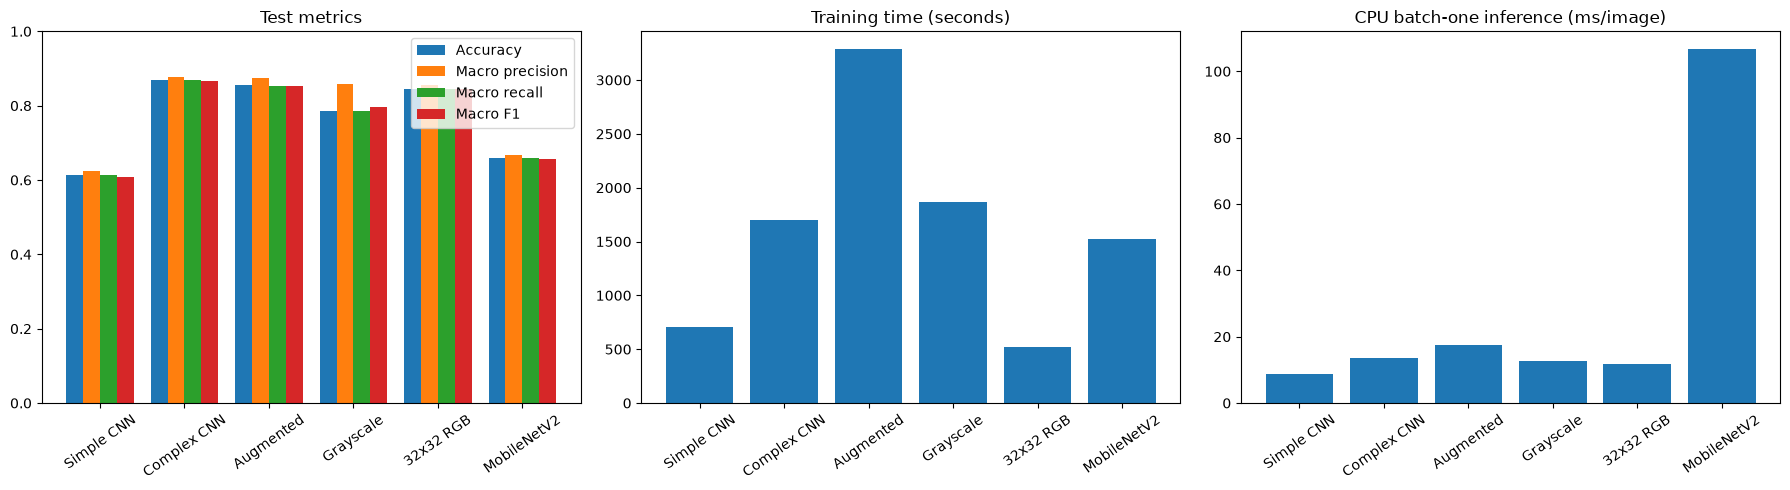

In [ ]:
configuration_names = {
    "simple_cnn_rgb64": "Simple CNN",
    "complex_cnn_rgb64": "Complex CNN",
    "complex_cnn_augmented": "Augmented",
    "complex_cnn_grayscale": "Grayscale",
    "complex_cnn_rgb32": "32x32 RGB",
    "pretrained_cnn_rgb64": "MobileNetV2"
}

labels = full_comparison["data_variant"].map(configuration_names)
positions = np.arange(len(full_comparison))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for offset, (column, label) in enumerate((
    ("test_accuracy", "Accuracy"),
    ("test_macro_precision", "Macro precision"),
    ("test_macro_recall", "Macro recall"),
    ("test_macro_f1", "Macro F1"),
)):
    axes[0].bar(
        positions + (offset - 1.5) * 0.2,
        full_comparison[column],
        width=0.2,
        label=label
    )

axes[0].set_xticks(positions, labels)
axes[0].set_ylim(0, 1)
axes[0].set_title("Test metrics")
axes[0].legend()

for ax, column, title in zip(
    axes[1:],
    ("train_time_s", "inference_ms"),
    ("Training time (seconds)", "CPU batch-one inference (ms/image)")
):
    ax.bar(labels, full_comparison[column])
    ax.set_title(title)

for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)

fig.tight_layout()
plt.show()

### Inference speed and model complexity

The simple CNN achieved the lowest mean CPU inference latency of 8.81 ms per image but had substantially lower classification accuracy. The complex CNN achieved a mean latency of 13.54 ms per image while providing the highest classification accuracy.

The 32 x 32 complex CNN achieved a mean latency of 11.72 ms per image, providing a possible trade-off between classification accuracy and computational cost. MobileNetV2 had the highest mean inference latency of 106.71 ms per image.

Although the complex CNN contains more convolutional layers, it has fewer parameters than the simple CNN because global average pooling replaces the large flattened feature representation. Inference latency also depends on the operations performed by the architecture, not only its parameter count.

These measurements were collected on CPU and may vary depending on hardware and system workload. They do not include the full webcam capture and hand-detection pipeline.

### Training and validation curves

The following figures show training and validation accuracy and loss across 10 epochs for each experimental configuration. These curves help identify convergence and potential overfitting.

simple_cnn_rgb64


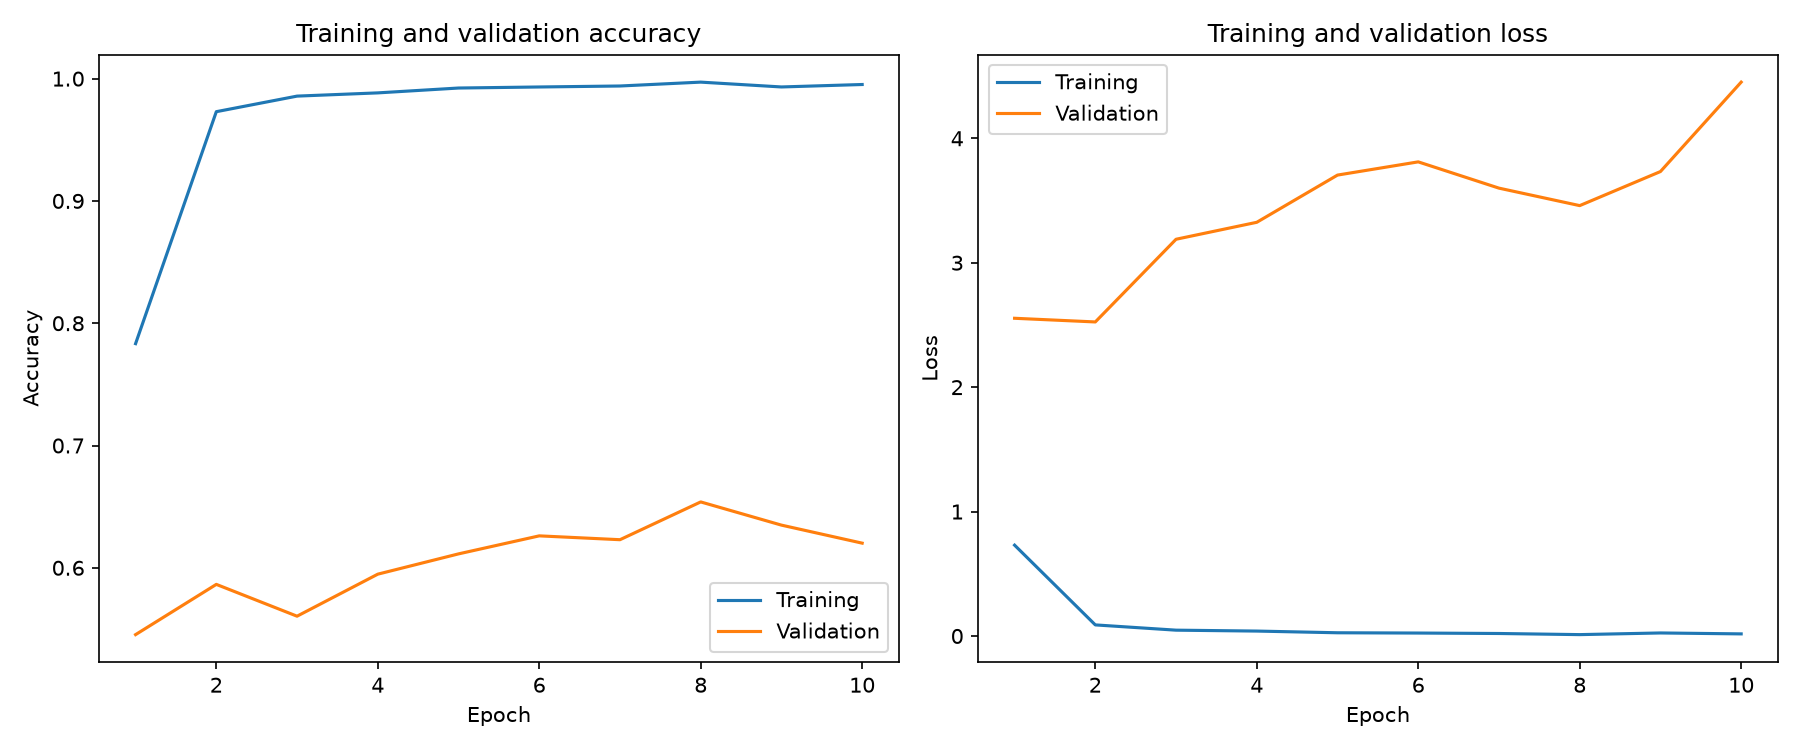

complex_cnn_rgb64


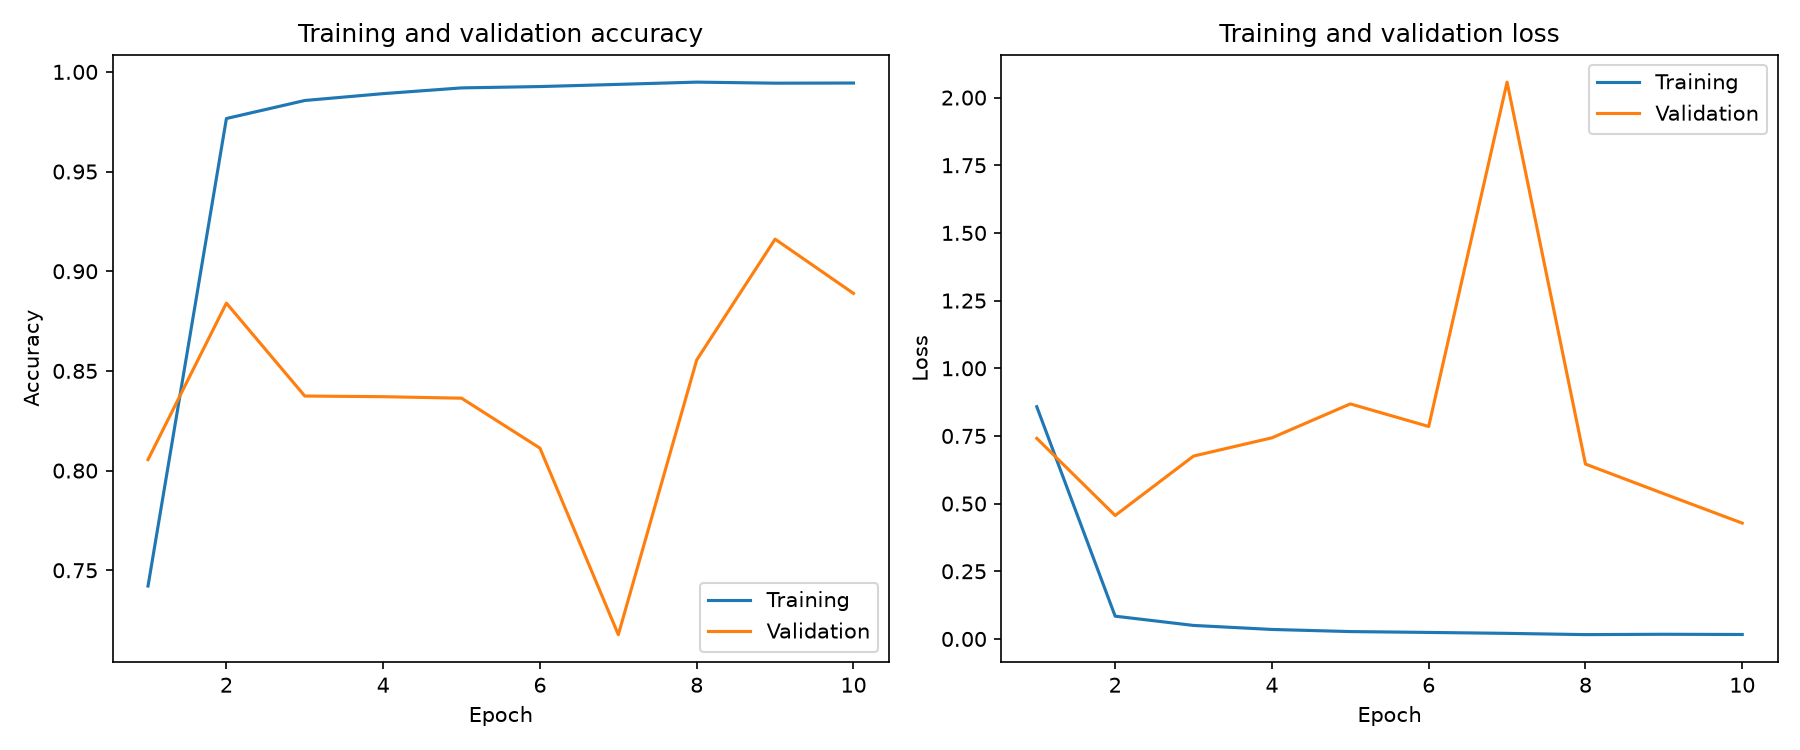

complex_cnn_augmented


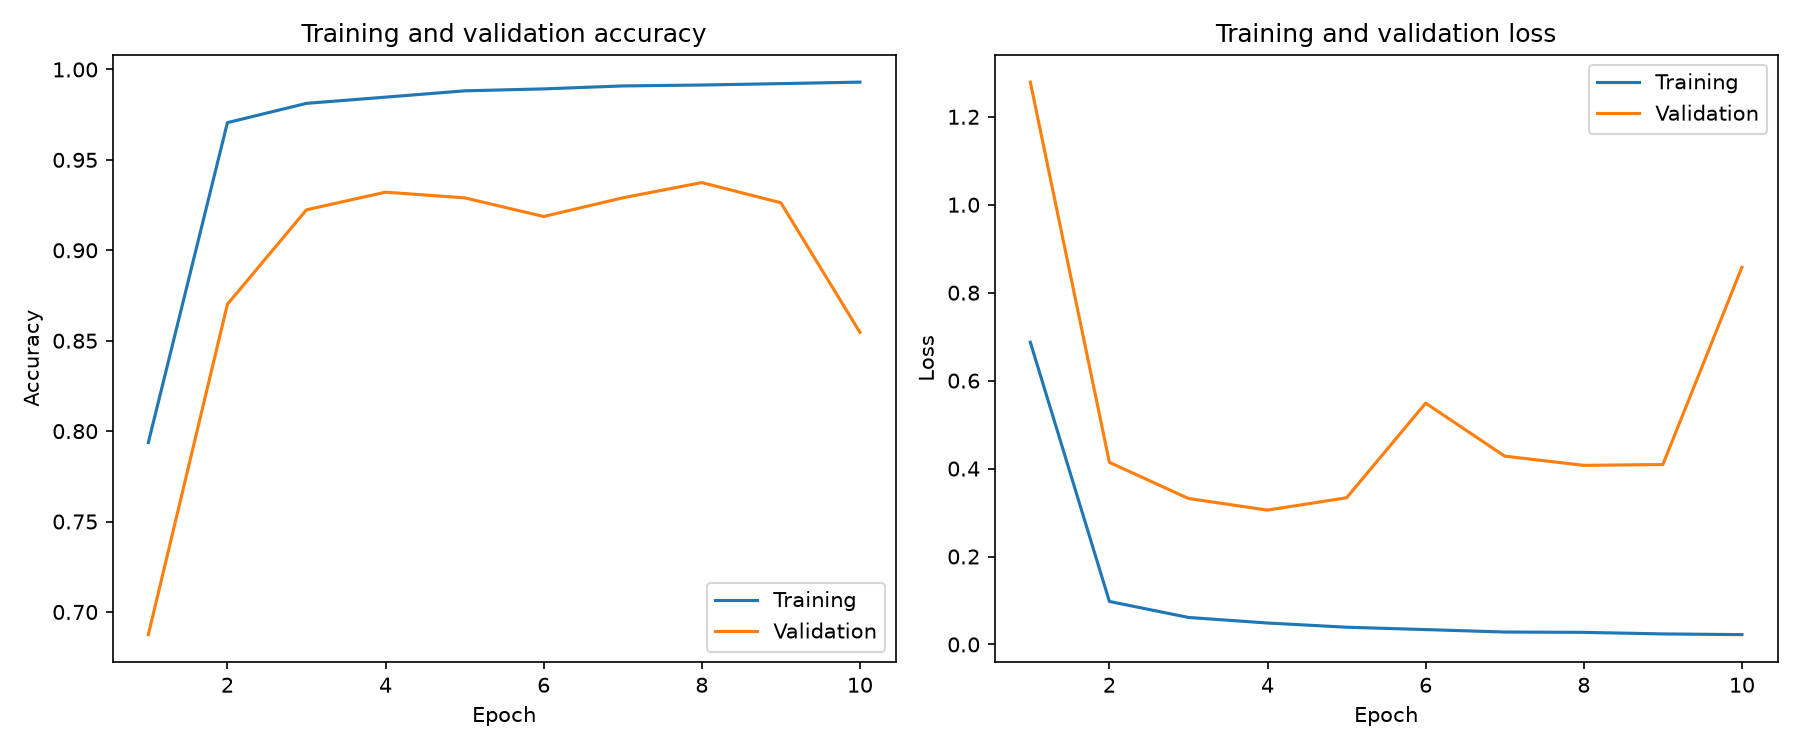

complex_cnn_grayscale


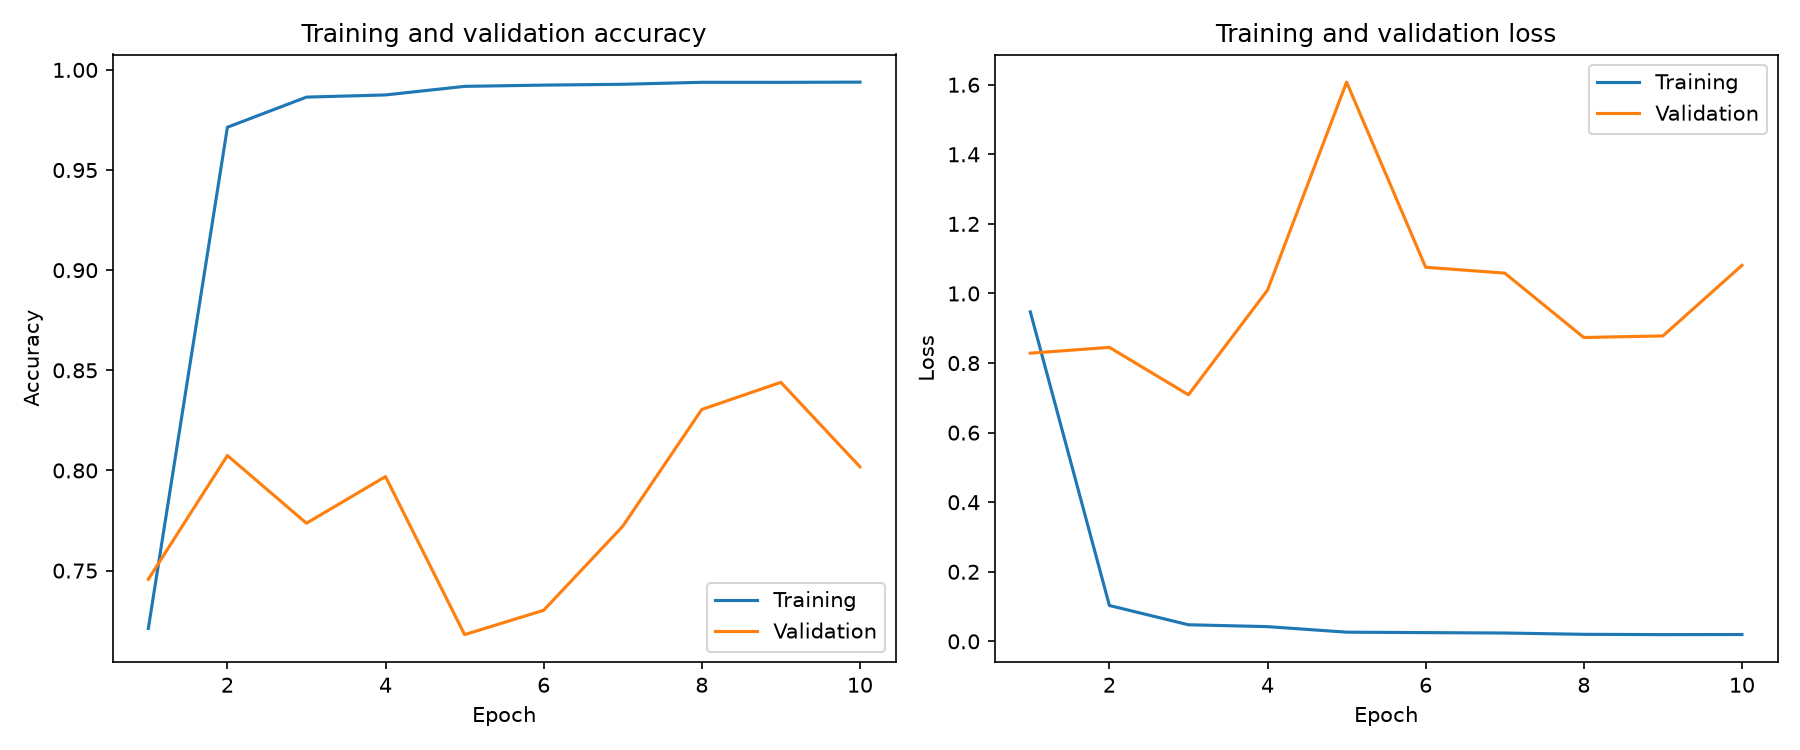

complex_cnn_rgb32


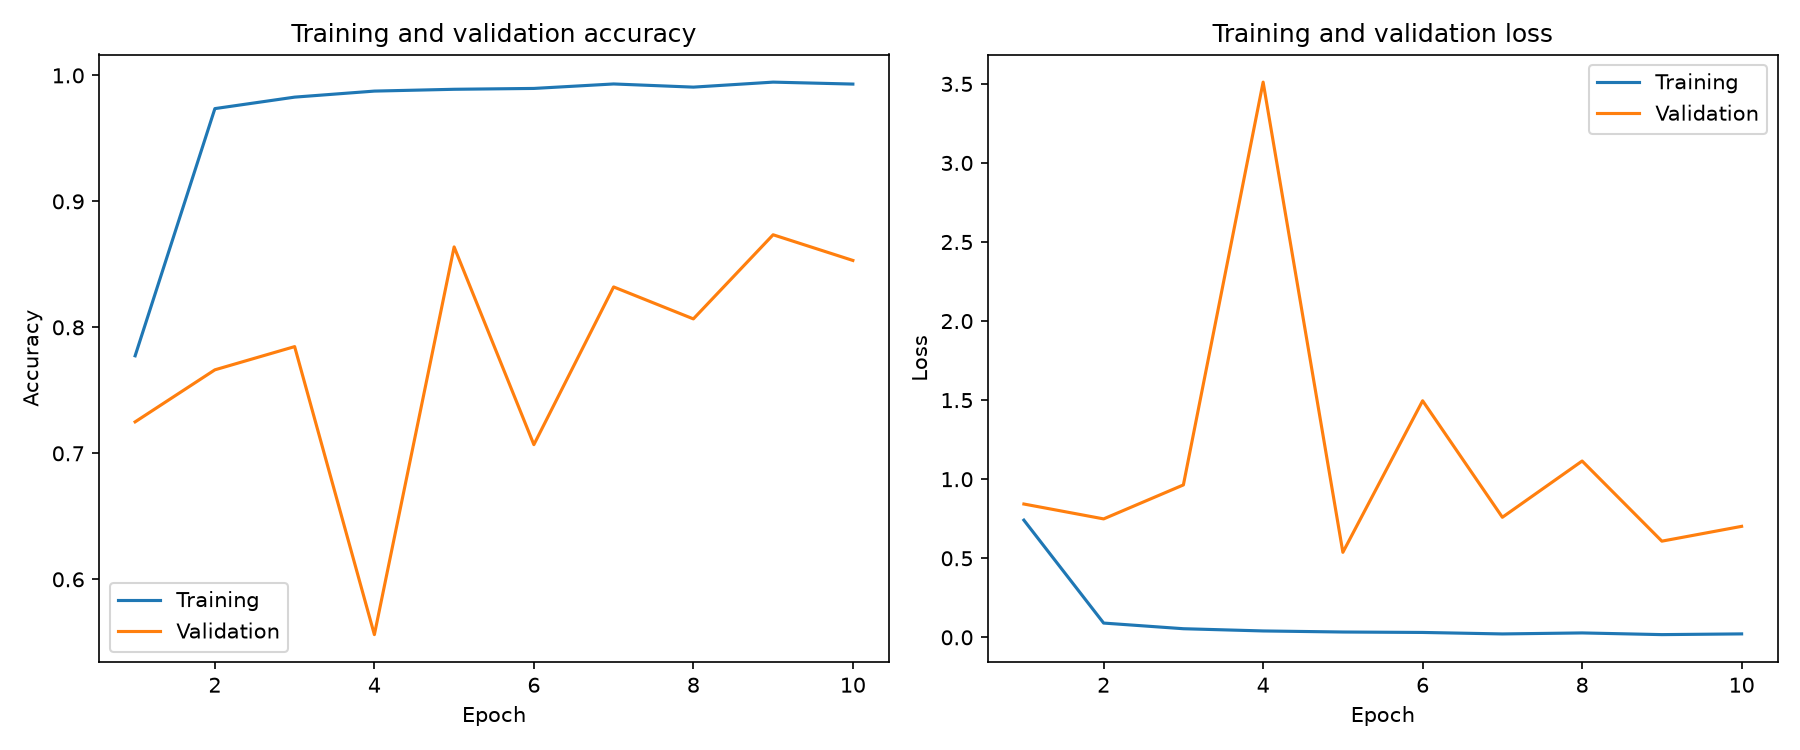

complex_cnn_10class


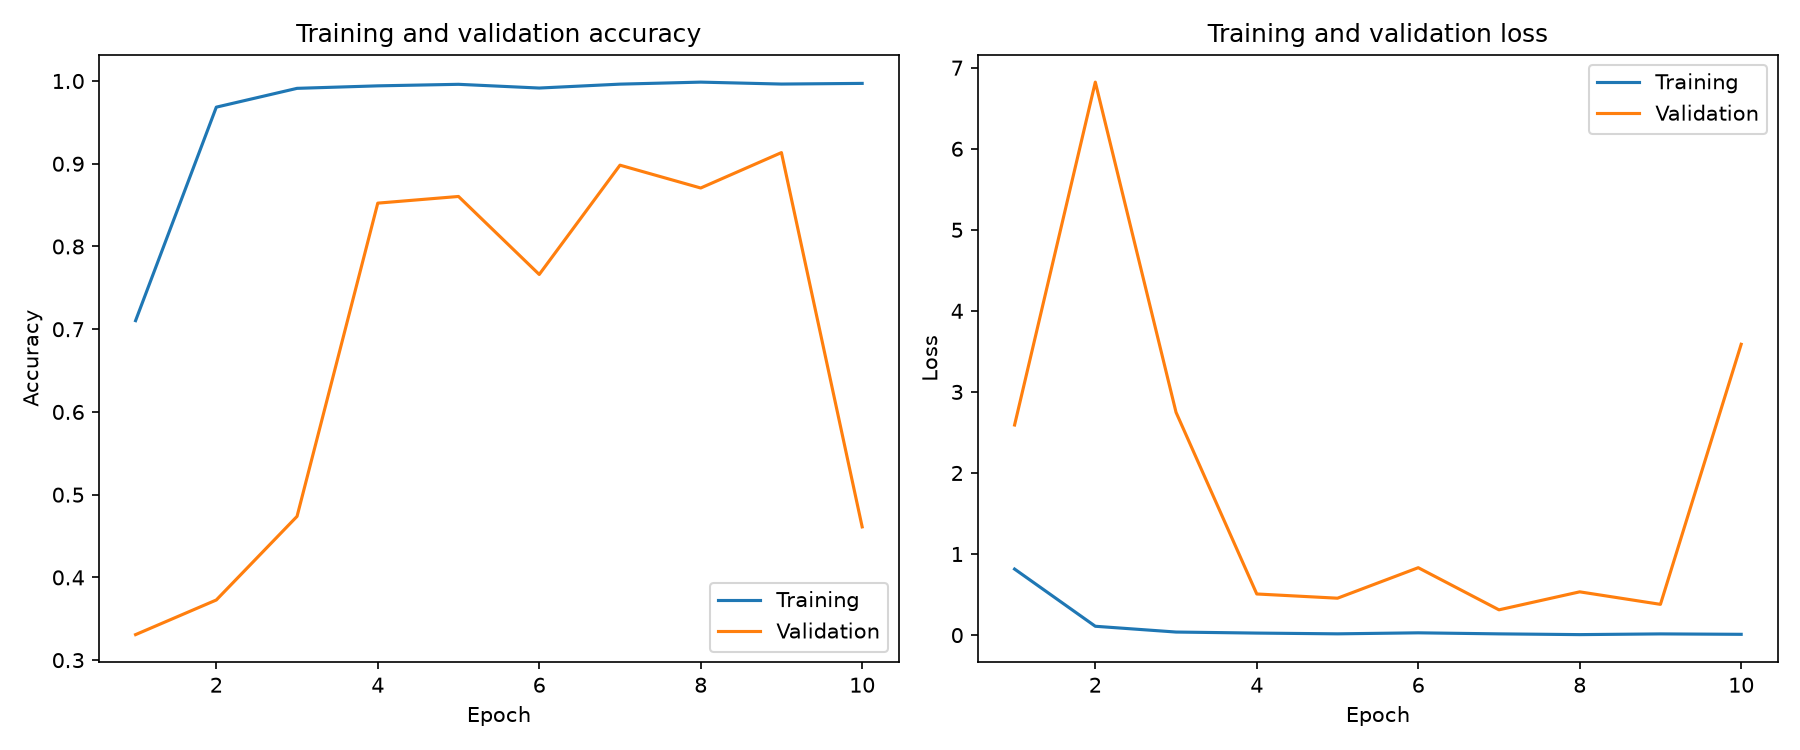

pretrained_cnn_rgb64


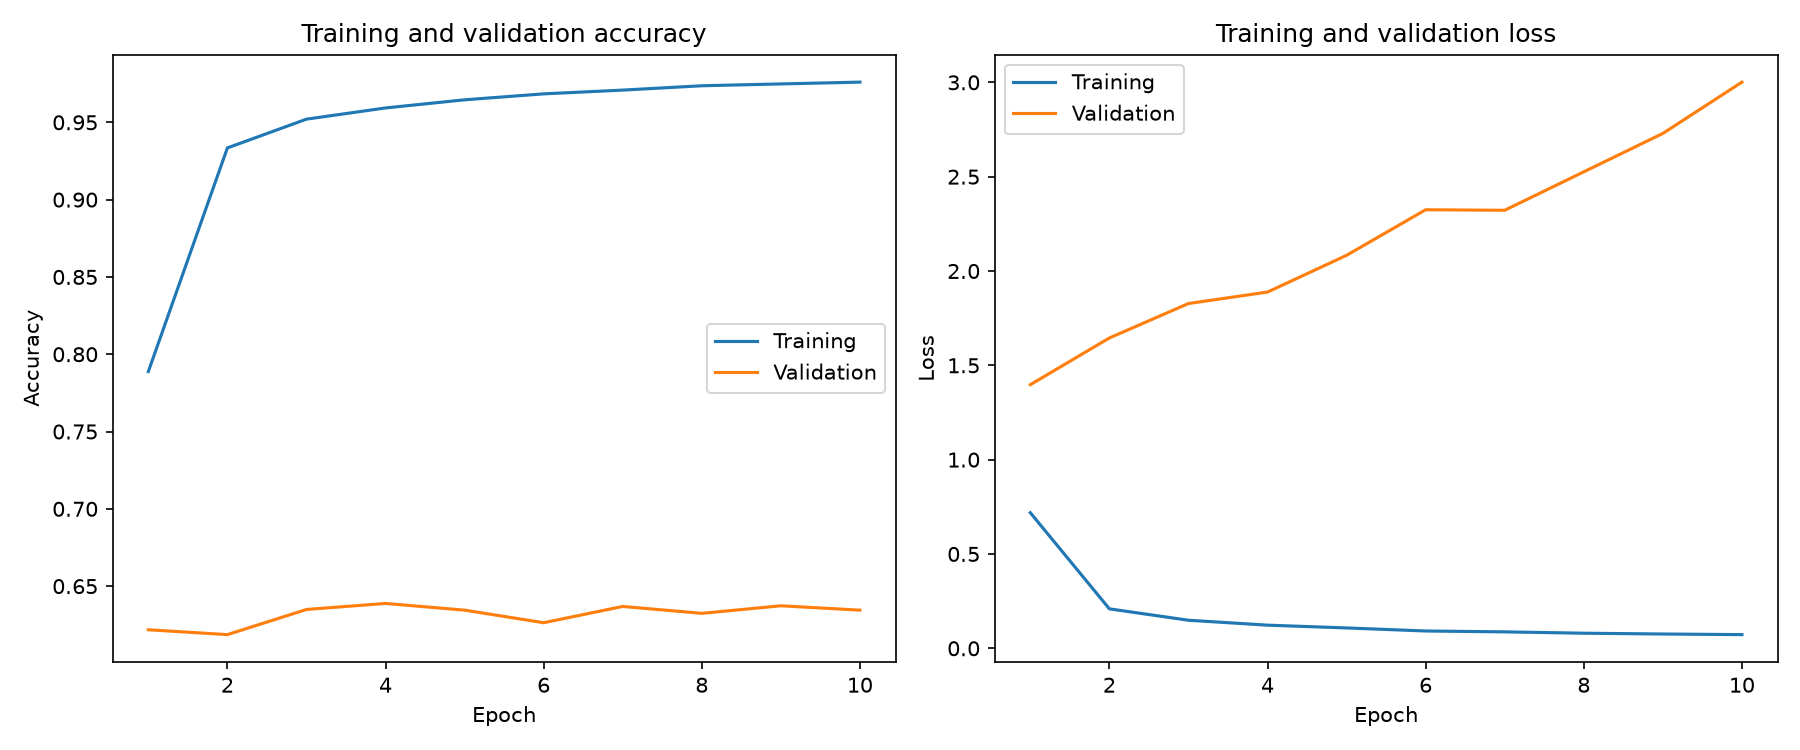

In [ ]:
for run_id in comparison["run_id"]:
    print(run_id.replace("experiment2_", ""))

    display(Image(
        filename=str(
            ARTIFACT_DIR / f"{run_id}_training_curves.png"
        )
    ))

### Interpreting the training curves

The simple CNN achieved high training accuracy but substantially lower validation accuracy, indicating overfitting. The complex CNN achieved higher validation accuracy, suggesting improved generalization under the selected architecture and training settings.

The augmented, grayscale, and reduced-resolution configurations also show differences between training and validation performance. The 10-class configuration demonstrates substantial overfitting, reaching approximately 99.71% training accuracy but only 46.11% validation accuracy.

The pretrained MobileNetV2 model uses a frozen convolutional base, which limits its ability to adapt pretrained features to the ASL Alphabet dataset.

The final-epoch weights are used consistently across all configurations. Earlier validation peaks suggest that checkpoint selection or early stopping could be investigated in future experiments.

## 3. Confusion analysis and limitations

### Error analysis: which letters are confused?

The complex CNN trained on 64 x 64 RGB images has the highest validation accuracy and is selected for further analysis. The normalized confusion matrix and ranked confusion pairs below are generated from its saved test report.

The confusion pairs are directed from the true letter to the predicted letter. The confusion matrix rows are normalized by true class, so diagonal values represent per-class recall.

![Complex CNN normalized test confusion matrix](results/experiment2/experiment2_complex_cnn_rgb64_confusion.png)

These images are video frames rather than independent samples from different signers. Repeated confusion patterns may reflect similarities between neighboring frames as well as similarities between hand shapes.

In [ ]:
best_run_id = best_validation["run_id"]

report_path = RESULTS_DIR / f"{best_run_id}_test.json"

best_test = json.loads(
    report_path.read_text(encoding="utf-8")
)

print("Selected CNN:", best_run_id)
print(f"Validation accuracy: {best_validation['val_accuracy']:.2%}")
print(f"Test accuracy: {best_validation['test_accuracy']:.2%}")

print("Most frequent directed confusions:")
display(evaluate.top_confusions(best_test, k=10))

per_class = pd.DataFrame(best_test["per_class"]).T
per_class.index.name = "letter"

print("Lowest-recall classes:")
display(
    per_class.sort_values("recall").head(8).style.format({
        "precision": "{:.1%}",
        "recall": "{:.1%}",
        "f1": "{:.1%}",
        "support": "{:.0f}"
    })
)

Selected CNN: experiment2_complex_cnn_rgb64
Validation accuracy: 88.89%
Test accuracy: 86.78%
Most frequent directed confusions:


,true,predicted,count
0,S,X,152
1,N,M,125
2,U,R,81
3,H,G,66
4,del,Q,65
5,T,L,57
6,X,U,43
7,G,H,40
8,E,A,39
9,D,F,34


Lowest-recall classes:


,precision,recall,f1,support
letter,,,,
S,84.1%,45.4%,59.0%,350
N,78.7%,45.7%,57.8%,300
E,87.4%,72.0%,79.0%,300
U,79.6%,72.7%,76.0%,300
del,100.0%,75.4%,86.0%,350
T,84.0%,77.0%,80.3%,300
H,85.4%,78.0%,81.5%,300
X,57.3%,78.3%,66.2%,300


### Interpreting the errors and limitations

The most frequent directed confusions include S -> X (152 predictions), N -> M (125 predictions), U -> R (81 predictions), and H -> G (66 predictions). Similar hand shapes and subtle differences in finger positioning may contribute to these errors. For example, M and N have similar closed-hand shapes, while G and H differ in finger positioning. These are plausible explanations rather than confirmed causes.

Several limitations should be considered when interpreting the results. All dataset images come from one signer and room, so the fixed test scores do not establish performance on new signers or webcam conditions. Resizing images may also remove fine details that are important for distinguishing similar signs.

Each configuration was trained once for 10 epochs using fixed hyperparameters. The experiments do not measure variability across random seeds or alternative training settings. Augmentation increases the number of training steps, and the pretrained MobileNetV2 model uses frozen weights rather than fine-tuning.

Future experiments could investigate early stopping, pretrained-model fine-tuning, alternative augmentation settings, and evaluation on independently collected images from different signers and environments.

### Conclusion

The complex CNN using 64 x 64 RGB images without augmentation achieved the best overall validation performance, with 88.89% validation accuracy, 86.78% test accuracy, and a macro F1 score of 86.54%. Its mean CPU inference latency of 13.54 ms per image provides a reasonable balance between classification accuracy and computational cost.

The 32 x 32 complex CNN provides an alternative when reduced training time and computational requirements are important. Under the selected training settings, the custom complex CNN also outperformed the frozen pretrained MobileNetV2 model.

The selected model is saved as `results/experiment2_complex_cnn_rgb64_model.keras` and can be used through the shared prediction interface implemented in `cnn_model.py`. All evaluation reports, training histories, comparison figures, and confusion analysis results are saved under `results/experiment2/` and `results/`.